In [1]:
!pip -q install kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "avineshprabhakaran/loan-eligibility-prediction",
    "Loan Eligibility Prediction.csv"
)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'loan-eligibility-prediction' dataset.
Dataset downloaded successfully!
Dataset shape: (614, 13)


,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [2]:

# Display dataset shape (rows, columns)
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical summary:")
display(df.describe(include='all'))

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Display target distribution
if 'Loan_Status' in df.columns:
    print("\nLoan status distribution:")
    print(df['Loan_Status'].value_counts())


Dataset shape: (614, 13)

Column names:
['Customer_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         614 non-null    int64  
 1   Gender              614 non-null    object 
 2   Married             614 non-null    object 
 3   Dependents          614 non-null    int64  
 4   Education           614 non-null    object 
 5   Self_Employed       614 non-null    object 
 6   Applicant_Income    614 non-null    int64  
 7   Coapplicant_Income  614 non-null    float64
 8   Loan_Amount         614 non-null    int64  
 9   Loan_Amount_Term    614 non-null    int64  
 10  Credit_History      614 non-null

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,614.000000,614,614,614.000000,614,614,614.000000,614.000000,614.000000,614.000000,614.000000,614,614
unique,NaN,2,2,NaN,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,NaN,Male,Yes,NaN,Graduate,No,NaN,NaN,NaN,NaN,NaN,Semiurban,Y
freq,NaN,499,399,NaN,480,523,NaN,NaN,NaN,NaN,NaN,233,422
mean,307.500000,NaN,NaN,0.856678,NaN,NaN,5403.459283,1621.245798,142.022801,338.892508,0.850163,NaN,NaN
std,177.390811,NaN,NaN,1.216651,NaN,NaN,6109.041673,2926.248369,87.083089,69.716355,0.357203,NaN,NaN
min,1.000000,NaN,NaN,0.000000,NaN,NaN,150.000000,0.000000,9.000000,12.000000,0.000000,NaN,NaN
25%,154.250000,NaN,NaN,0.000000,NaN,NaN,2877.500000,0.000000,98.000000,360.000000,1.000000,NaN,NaN
50%,307.500000,NaN,NaN,0.000000,NaN,NaN,3812.500000,1188.500000,125.000000,360.000000,1.000000,NaN,NaN
75%,460.750000,NaN,NaN,2.000000,NaN,NaN,5795.000000,2297.250000,164.750000,360.000000,1.000000,NaN,NaN



Duplicate rows: 0

Loan status distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [3]:

# Separate input features and target

target_column = 'Loan_Status'

if target_column not in df.columns:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

# Remove rows where the target is missing
df = df.dropna(subset=[target_column]).copy()

# Remove an ID column if present because it is not a useful predictor
X = df.drop(
    columns=[target_column, 'Loan_ID'],
    errors='ignore'
)

Y = df[target_column].map({'N': 0, 'Y': 1})

# Check the results
print("X shape:", X.shape)
print("Y shape:", Y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget values:")
print(Y.value_counts())


X shape: (614, 12)
Y shape: (614,)

Input features:
['Customer_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target values:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 491
Testing rows: 123


In [5]:

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

# Process numerical columns
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Process categorical columns
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])

# Fit on training data; transform both sets
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Convert to dense arrays for Keras
X_train_scaled = X_train_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

# Convert sparse matrices if necessary
if hasattr(X_train_scaled, 'toarray'):
    X_train_scaled = X_train_scaled.toarray()

if hasattr(X_test_scaled, 'toarray'):
    X_test_scaled = X_test_scaled.toarray()

print("Processed training shape:", X_train_scaled.shape)
print("Processed testing shape:", X_test_scaled.shape)


Numerical columns: ['Customer_ID', 'Dependents', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns: ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']
Processed training shape: (491, 18)
Processed testing shape: (123, 18)


In [6]:

from keras.models import Sequential
from keras.layers import Dense, Input

# Determine the number of input features after encoding
number_of_features = X_train_scaled.shape[1]

# Create the ANN
ann = Sequential([
    Input(shape=(number_of_features,)),

    # First hidden layer
    Dense(16, activation='relu'),

    # Second hidden layer
    Dense(8, activation='relu'),

    # Output layer
    Dense(1, activation='sigmoid')
])

# Compile the model
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
ann.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 449 (1.75 KB)

 Trainable params: 449 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history = ann.fit(
    X_train_scaled,
    Y_train,
    batch_size=16,
    epochs=50,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.4107 - loss: 0.7245 - val_accuracy: 0.5354 - val_loss: 0.7066
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5765 - loss: 0.6922 - val_accuracy: 0.6364 - val_loss: 0.6844
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6837 - loss: 0.6681 - val_accuracy: 0.7071 - val_loss: 0.6642
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7270 - loss: 0.6458 - val_accuracy: 0.7273 - val_loss: 0.6414
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7398 - loss: 0.6191 - val_accuracy: 0.7374 - val_loss: 0.6178
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7577 - loss: 0.5900 - val_accuracy: 0.7374 - val_loss: 0.5888
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7730 - loss: 0.5585 - val_accuracy: 0.7475 - val_loss: 0.5636
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7985 - loss: 0.5283 - val_accuracy: 0.7475 - 

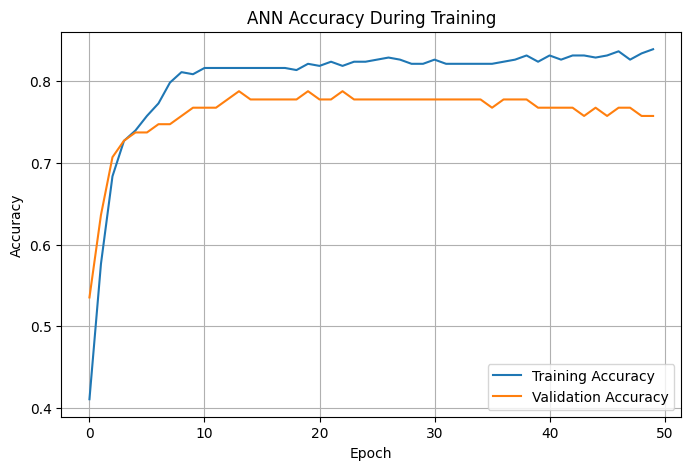

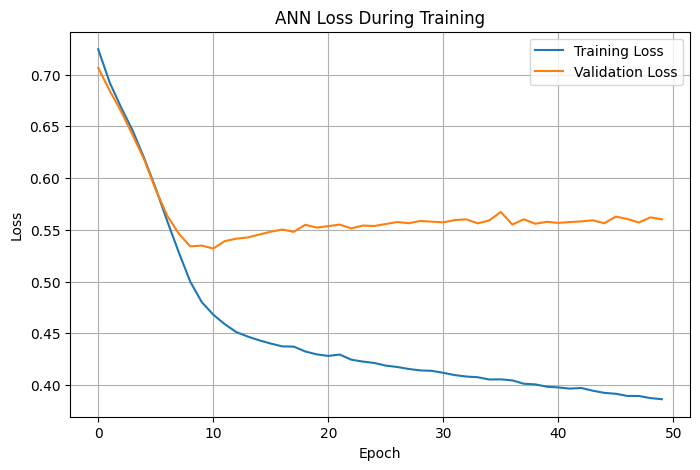

In [8]:

import matplotlib.pyplot as plt
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Accuracy During Training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Loss During Training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [9]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# Predict approval probabilities
probabilities = ann.predict(X_test_scaled)

# Convert probabilities into binary predictions
Y_pred = (probabilities >= 0.5).astype(int).ravel()

# Calculate accuracy
accuracy = accuracy_score(Y_test, Y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Display confusion matrix
cm = confusion_matrix(Y_test, Y_pred)
print("\nConfusion Matrix:\n", cm)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred, zero_division=0))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step
Test Accuracy: 78.86 %

Confusion Matrix:
 [[18 20]
 [ 6 79]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.47      0.58        38
           1       0.80      0.93      0.86        85

    accuracy                           0.79       123
   macro avg       0.77      0.70      0.72       123
weighted avg       0.78      0.79      0.77       123



In [11]:
%pip install --force-reinstall scikit-learn==1.5.2

  Using cached scikit_learn-1.5.2-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (13 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.5.2-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.0 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall

In [12]:
import sklearn
import scikeras

print("Scikit-learn:", sklearn.__version__)
print("SciKeras:", scikeras.__version__)

Scikit-learn: 1.5.2
SciKeras: 0.13.0


In [13]:

from scikeras.wrappers import KerasClassifier

from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import RandomizedSearchCV

# Build a fresh model for every training run
def build_classifier():
    model = Sequential([
        Input(shape=(number_of_features,)),
        Dense(16, activation='relu'),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


classifier = KerasClassifier(
    model=build_classifier,
    verbose=0
)

# Define the hyperparameters
parameters = {
    'batch_size': [8, 16, 32],
    'epochs': [10, 20, 30]
}

# Search a subset of combinations
random_search2 = RandomizedSearchCV(
    estimator=classifier,
    param_distributions=parameters,
    n_iter=4,
    scoring='accuracy',
    cv=3,
    n_jobs=1,
    random_state=42
)

# Train and search
random_search2.fit(X_train_scaled, Y_train)

print("Best parameters:", random_search2.best_params_)
print("Best CV accuracy:", round(random_search2.best_score_ * 100, 2), "%")


Best parameters: {'epochs': 10, 'batch_size': 8}
Best CV accuracy: 80.44 %


In [14]:
# Step 11: Predict loan eligibility for a new applicant

import pandas as pd
import numpy as np

# Create a new applicant using the same input columns as X_train
new_applicant = pd.DataFrame([{
    column: X_train[column].median()
    if pd.api.types.is_numeric_dtype(X_train[column])
    else X_train[column].mode()[0]
    for column in X_train.columns
}])

# Display the applicant's data
print("New Applicant:")
display(new_applicant)

New Applicant:


,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area
0,316.0,Male,Yes,0.0,Graduate,No,3762.0,1255.0,124.0,360.0,1.0,Semiurban


In [15]:
# Apply the existing preprocessing pipeline
new_applicant_scaled = preprocessor.transform(new_applicant)

# Convert sparse output to a dense array if needed
if hasattr(new_applicant_scaled, "toarray"):
    new_applicant_scaled = new_applicant_scaled.toarray()

print("Processed input shape:", new_applicant_scaled.shape)

Processed input shape: (1, 18)


In [17]:
# Get the best trained ANN model from RandomizedSearchCV
model = random_search2.best_estimator_.model_

# Predict probability of loan approval
probability = model.predict(new_applicant_scaled, verbose=0)[0][0]

# Convert probability into a class
prediction = 1 if probability >= 0.5 else 0

print("Approval probability:", round(float(probability) * 100, 2), "%")

if prediction == 1:
    print("ANN Prediction: Loan likely to be approved")
else:
    print("ANN Prediction: Loan likely to be rejected")

Approval probability: 87.51 %
ANN Prediction: Loan likely to be approved


In [18]:
# Final model performance summary

test_loss, test_accuracy = model.evaluate(X_test_scaled, Y_test, verbose=0)

print("Final ANN Model Results")
print("-----------------------")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Final ANN Model Results
-----------------------
Test Accuracy: 79.67%
Test Loss: 0.4988
